# Phase retrieval by transport of intensity

Three calibrated IL1 exposures supply an in-focus intensity and an axial intensity derivative. A **linear variable-intensity TIE solve** reconstructs phase on pixels. This uses the same modified-smiley Gaussian wave as the earlier example. See [TIE_README.md](TIE_README.md) for the assumptions and numerical checks.

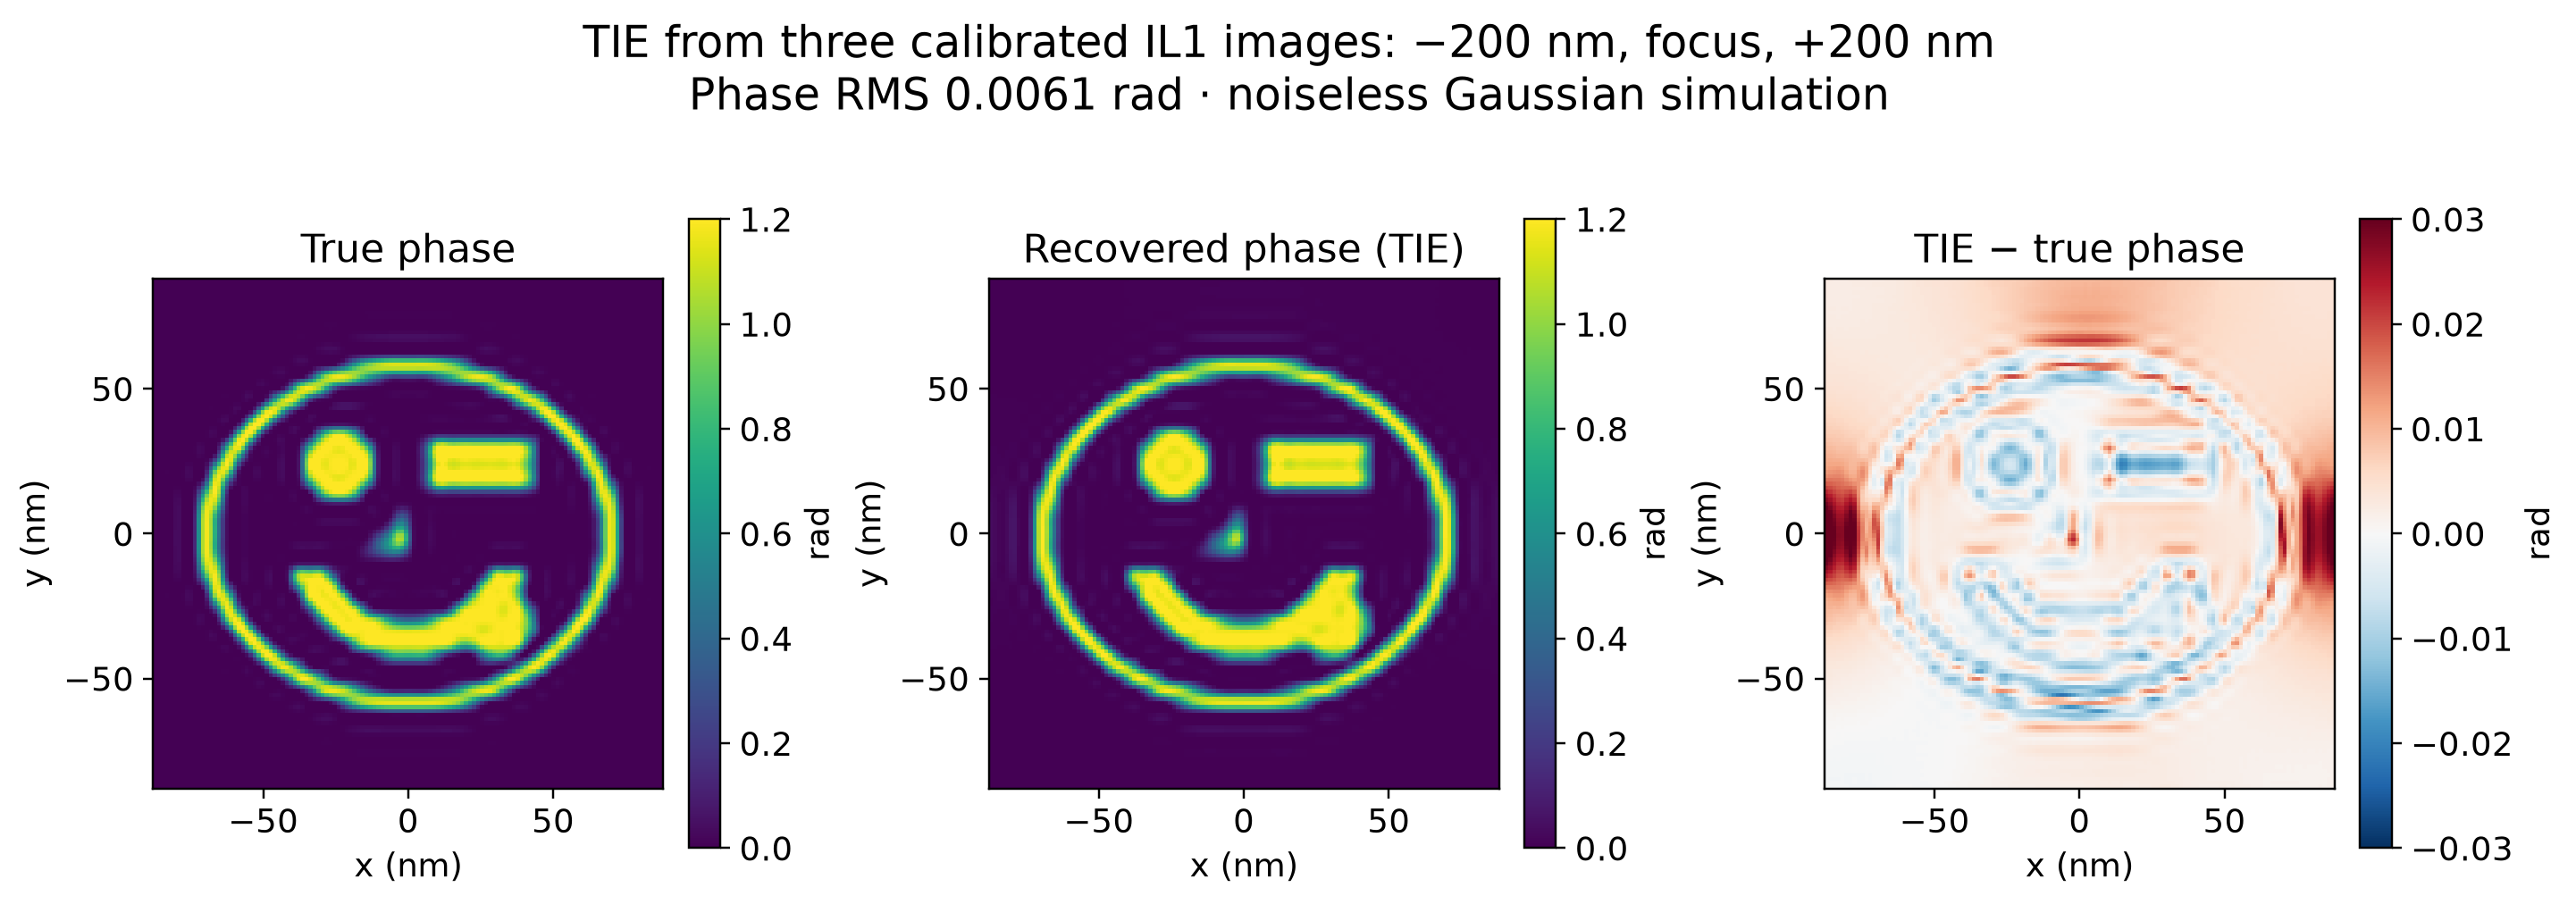

In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import Image, display
repo = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/temgym_core').is_dir())
folder = repo/'examples/phase_retrieval_demonstration'
data = np.load(folder/'tie_dataset.npz')
report = json.loads((folder/'tie_results.json').read_text())
display(Image(filename=str(folder/'figures/06_TIE_phase_retrieval.png')))

## Three-image acquisition

The camera is fixed at 256 × 256 samples. IL1 is set for specimen-equivalent defocus −200 nm, zero and +200 nm. The calibrated A matrix corrects image magnification, rotation and intensity area scaling before differentiation. A central 128 × 128 specimen-coordinate crop supplies the TIE domain.

Defocus (nm)   IL1 (A)    magnification    rotation (deg)
    -200.0   2.166455887     37782.44     -3.5742
      +0.0   2.205677875     40000.00     -0.0000
    +200.0   2.248973896     42494.10     +3.9454


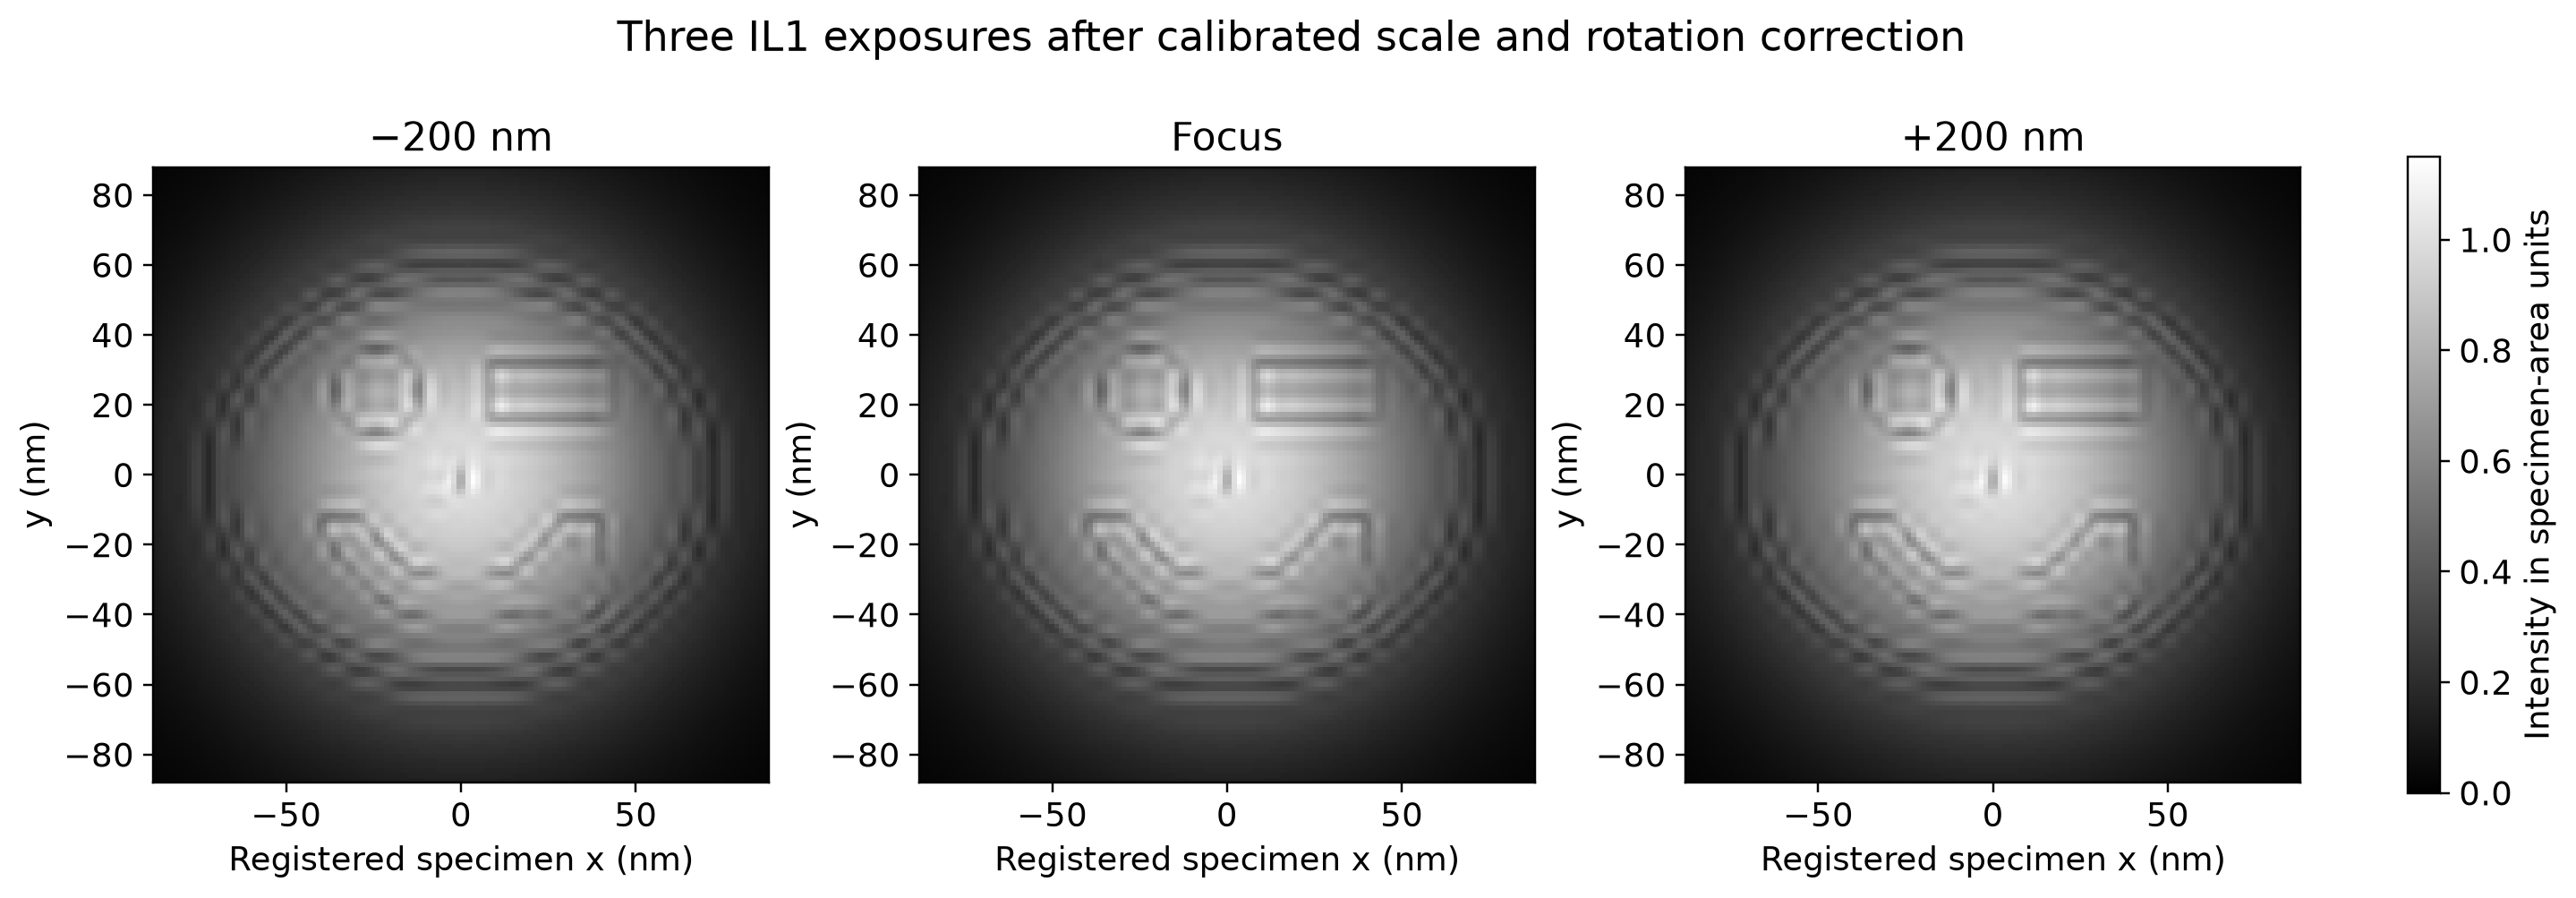

In [2]:
print('Defocus (nm)   IL1 (A)    magnification    rotation (deg)')
for j in [0,2,4]:
    r=report['settings'][j]
    print(f"{r['effective_defocus_m']*1e9:+10.1f}   {r['current_A']:.9f}   {r['magnification']:10.2f}     {r['rotation_deg']:+.4f}")
display(Image(filename=str(folder/'figures/06b_TIE_registered_images.png')))

## Solve the TIE

$$\nabla\cdot(I_0\nabla\phi)=-\frac{2\pi}{\lambda}\frac{I_+-I_-}{2\Delta z}.$$

The finite-volume solver uses the measured spatially varying intensity and zero normal phase-current flux at the crop boundary. The phase has an arbitrary constant. Ground truth is used only for piston alignment and scoring, not as input to the inverse. No Gaussian coefficients are fitted.

In [3]:
import sys
if str(folder) not in sys.path:
    sys.path.insert(0,str(folder))
from tie_demonstration import solve_tie
z=data['effective_defocus_m']
derivative=(data['registered_intensities'][4]-data['registered_intensities'][0])/(z[4]-z[0])
phase, checks=solve_tie(data['registered_intensities'][2],derivative,
                        report['wavelength_m'],float(data['specimen_pitch_m']))
# Truth is used only after the solve, for a gauge-invariant comparison.
mask=data['mask']; truth=data['true_phase']
phase-=np.mean((phase-truth)[mask])
np.testing.assert_allclose(phase,data['reconstructed_phases'][0],atol=1e-9)
print('Phase RMS:',np.sqrt(np.mean((phase-truth)[mask]**2)),'rad')
print('Linear-system residual:',checks['linear_residual'])

Phase RMS: 0.006087620539138955 rad
Linear-system residual: 4.162429492654434e-15


## Validation and scope

An additional ±100 nm pair checks the derivative step: it is excluded from the main three-image reconstruction. The images are noiseless, with ideal optics. The sample remains the phase-remapped smiley represented by 2,304 Gaussian beamlets; this is not a beamlet-convergence test or a reconstruction of the original complex `smiley()` function. Propagation omits the unobservable common axial carrier to preserve small relative optical actions.

In [4]:
print(json.dumps(report['metrics'],indent=2))

[
  {
    "linear_residual": 4.162429492654434e-15,
    "removed_rhs_mean": 6.840432530696734e-07,
    "compatibility_correction_fraction": 1.5264179127684102e-05,
    "step_nm": 199.9999999999843,
    "phase_rmse_rad": 0.006087620539138955,
    "phase_correlation": 0.9999161154853139
  },
  {
    "linear_residual": 4.2020483334070934e-15,
    "removed_rhs_mean": 7.013799285895711e-07,
    "compatibility_correction_fraction": 1.5636951389472595e-05,
    "step_nm": 100.00000000007033,
    "phase_rmse_rad": 0.006236257057580387,
    "phase_correlation": 0.9999120552260287
  }
]


## Regenerate the acquisition and figures

The saved-data inverse above is a sparse CPU solve. The forward Gaussian simulation uses the available JAX device.

In [5]:
# import subprocess
# subprocess.run([sys.executable,str(folder/'tie_demonstration.py')],check=True)